# 13 — XGBoost Classifier dan Regressor

**Tujuan model.** XGBoost menggabungkan pohon keputusan dalam proses gradient boosting dan menambahkan regularisasi kompleksitas pohon. Model baru dibangun untuk memperbaiki fungsi objektif pada iterasi sebelumnya.

**Rumus fungsi objektif.** $$(\mathcal{L}=\sum_i l(y_i,\hat y_i)+\sum_t\Omega(f_t))$$ dengan $(l)$ sebagai loss prediksi dan $(\Omega)$ sebagai penalti kompleksitas pohon.

**Kesesuaian dengan data.** XGBoost sering digunakan untuk data tabular dan dapat memodelkan hubungan non-linear antarfitur histori penjualan, hari, produk, dan outlet. Dalam notebook ini fitur kategorikal di-one-hot encoding dan pohon memakai `tree_method='hist'`.

**Referensi:** Chen, T. & Guestrin, C. (2016). *XGBoost: A Scalable Tree Boosting System*. Proceedings of the 22nd ACM SIGKDD International Conference on Knowledge Discovery and Data Mining, 785–794. https://doi.org/10.1145/2939672.2939785

Paper ini adalah publikasi prosiding konferensi ilmiah. Struktur kode disamakan dengan notebook eksperimen yang sudah ada.

## 0. Persiapan lingkungan


In [1]:
%pip -q install xgboost

Note: you may need to restart the kernel to use updated packages.


## 1. Import pustaka dan konfigurasi

In [ ]:
import os
import glob
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy import sparse
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    mean_absolute_error, mean_squared_error, r2_score
)
from sklearn.base import clone

SEED = 42
np.random.seed(SEED)
warnings.filterwarnings('ignore', category=FutureWarning)
pd.set_option('display.max_columns', 100)
pd.set_option('display.width', 160)

FOLDER = 'Clustering_Stok'
MAX_EVAL_ROWS = 1500   # ubah menjadi None untuk memakai seluruh data uji

from xgboost import XGBClassifier, XGBRegressor

## 2. Memuat data hasil preprocessing


In [3]:
def cari_file_harian():
    """Cari hasil dari 00_Preprocessing.ipynb di struktur folder project Quiz."""
    kandidat = [
        os.path.join(FOLDER, 'daily_sales_timeseries.csv'),
        os.path.join('Quiz', FOLDER, 'daily_sales_timeseries.csv'),
        os.path.join('/content', FOLDER, 'daily_sales_timeseries.csv'),
        os.path.join('/content/Quiz', FOLDER, 'daily_sales_timeseries.csv'),
    ]
    for path in kandidat:
        if os.path.isfile(path):
            return path

    semua = glob.glob('/content/**/daily_sales_timeseries.csv', recursive=True)
    semua += glob.glob('./**/daily_sales_timeseries.csv', recursive=True)
    semua = list(dict.fromkeys(os.path.abspath(p) for p in semua if os.path.isfile(p)))
    if semua:
        # Prioritaskan file yang berada di dalam folder Clustering_Stok.
        semua.sort(key=lambda p: (FOLDER not in p.replace('\\', '/'), len(p)))
        return semua[0]

data_path = cari_file_harian()
OUTPUT_DIR = os.path.dirname(data_path) or FOLDER
os.makedirs(OUTPUT_DIR, exist_ok=True)

daily = pd.read_csv(data_path)
kolom_wajib = {'Outlet', 'Item', 'Date', 'qty'}
if not kolom_wajib.issubset(daily.columns):
    raise ValueError(f'Kolom data harus mencakup: {sorted(kolom_wajib)}')
daily['Date'] = pd.to_datetime(daily['Date'], errors='coerce')
daily['qty'] = pd.to_numeric(daily['qty'], errors='coerce')
daily = daily.dropna(subset=['Date', 'Outlet', 'Item', 'qty']).copy()
daily['Outlet'] = daily['Outlet'].astype(str)
daily['Item'] = daily['Item'].astype(str)
daily['qty'] = daily['qty'].clip(lower=0)
daily = daily.sort_values(['Outlet', 'Item', 'Date']).reset_index(drop=True)

print('File data        :', data_path)
print('Jumlah baris     :', f'{len(daily):,}')
print('Produk unik      :', daily['Item'].nunique())
print('Outlet           :', daily['Outlet'].nunique())
print('Rentang tanggal  :', daily['Date'].min().date(), 's/d', daily['Date'].max().date())


File data        : Clustering_Stok\daily_sales_timeseries.csv
Jumlah baris     : 76,704
Produk unik      : 94
Outlet           : 3
Rentang tanggal  : 2025-01-02 s/d 2025-09-30


## 3. Rekayasa fitur dan pembagian data

Fitur kalender dan lag hanya menggunakan nilai `qty` dari hari-hari sebelumnya. Data latih berisi tanggal awal, sedangkan tanggal terakhir dipakai untuk pengujian (split waktu 80:20). Kelas permintaan dibuat untuk eksperimen karena dataset asli tidak memiliki label klasifikasi.

In [4]:
# Fitur kalender
_daily = daily.copy()
_daily['dayofweek'] = _daily['Date'].dt.dayofweek
_daily['month'] = _daily['Date'].dt.month
_daily['day_of_month'] = _daily['Date'].dt.day
_daily['is_weekend'] = (_daily['dayofweek'] >= 5).astype(int)

# Fitur histori: shift(1) memastikan qty hari yang sedang diprediksi tidak dipakai.
_group = _daily.groupby(['Outlet', 'Item'], sort=False)['qty']
for lag in [1, 7, 14, 28]:
    _daily[f'lag_{lag}'] = _group.shift(lag)
for window in [7, 14, 28]:
    _daily[f'roll_mean_{window}'] = _daily.groupby(['Outlet', 'Item'], sort=False)['qty'].transform(
        lambda s, w=window: s.shift(1).rolling(window=w, min_periods=w).mean()
    )
for window in [7, 28]:
    _daily[f'roll_std_{window}'] = _daily.groupby(['Outlet', 'Item'], sort=False)['qty'].transform(
        lambda s, w=window: s.shift(1).rolling(window=w, min_periods=w).std(ddof=0)
    )

FITUR_NUM = [
    'dayofweek', 'month', 'day_of_month', 'is_weekend',
    'lag_1', 'lag_7', 'lag_14', 'lag_28',
    'roll_mean_7', 'roll_mean_14', 'roll_mean_28',
    'roll_std_7', 'roll_std_28'
]
FITUR_KAT = ['Outlet', 'Item']
FITUR = FITUR_NUM + FITUR_KAT

model_df = _daily.dropna(subset=FITUR_NUM).copy()
model_df['qty'] = model_df['qty'].round().astype(int)

# Kelas dibuat dari qty karena data asli tidak memiliki label kelas.
def ke_kelas_permintaan(qty):
    qty = np.asarray(qty)
    return np.where(qty == 0, 0, np.where(qty == 1, 1, 2)).astype(int)

# Split berdasarkan tanggal: tanggal terakhir menjadi data uji.
tanggal_unik = np.sort(model_df['Date'].unique())
if len(tanggal_unik) < 10:
    raise ValueError('Tanggal valid terlalu sedikit untuk split train/test berbasis waktu.')
pos_split = int(len(tanggal_unik) * 0.80)
tanggal_split = pd.Timestamp(tanggal_unik[pos_split])
train_df = model_df[model_df['Date'] < tanggal_split].copy()
test_df_full = model_df[model_df['Date'] >= tanggal_split].copy()

# Batasi jumlah baris evaluasi untuk mempercepat KNN; sampel sama antar-model.
if MAX_EVAL_ROWS is not None and len(test_df_full) > MAX_EVAL_ROWS:
    test_df = test_df_full.sample(n=MAX_EVAL_ROWS, random_state=SEED).sort_values(['Date', 'Outlet', 'Item']).copy()
else:
    test_df = test_df_full.copy()

X_train_raw = train_df[FITUR].copy()
X_test_raw = test_df[FITUR].copy()
y_cls_train = ke_kelas_permintaan(train_df['qty'])
y_cls_test = ke_kelas_permintaan(test_df['qty'])
y_reg_train = train_df['qty'].to_numpy(dtype=float)
y_reg_test = test_df['qty'].to_numpy(dtype=float)

print('Jumlah data latih       :', f'{len(train_df):,}')
print('Jumlah data uji penuh   :', f'{len(test_df_full):,}')
print('Baris yang dievaluasi   :', f'{len(test_df):,}')
print('Tanggal mulai pengujian :', tanggal_split.date())
print('Distribusi kelas latih  :', pd.Series(y_cls_train).value_counts().sort_index().to_dict())
print('Distribusi kelas uji    :', pd.Series(y_cls_test).value_counts().sort_index().to_dict())


Jumlah data latih       : 54,990
Jumlah data uji penuh   : 13,818
Baris yang dievaluasi   : 1,500
Tanggal mulai pengujian : 2025-08-13
Distribusi kelas latih  : {0: 25209, 1: 18348, 2: 11433}
Distribusi kelas uji    : {0: 722, 1: 493, 2: 285}


## 4. Pra-pemrosesan dan fungsi evaluasi

SVM/KNN/Naive Bayes dan model berbasis pohon selain CatBoost menerima data numerik yang distandarisasi dan kategori yang di-one-hot encoding. CatBoost memakai kategori langsung. Baseline disertakan untuk memastikan model kompleks dibandingkan dengan prediksi sederhana.

In [5]:
# Numerik distandarisasi; Outlet dan Item diubah menjadi one-hot encoding.
try:
    onehot = OneHotEncoder(handle_unknown='ignore', sparse_output=True)
except TypeError:  # kompatibilitas scikit-learn lama
    onehot = OneHotEncoder(handle_unknown='ignore', sparse=True)

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), FITUR_NUM),
        ('kat', onehot, FITUR_KAT),
    ],
    remainder='drop',
    sparse_threshold=0.3
)
X_train_encoded = preprocessor.fit_transform(X_train_raw)
X_test_encoded = preprocessor.transform(X_test_raw)

def ke_dense(X):
    return X.toarray() if sparse.issparse(X) else np.asarray(X)

print('Fitur setelah encoding :', X_train_encoded.shape[1])
print('Tipe matriks           :', type(X_train_encoded).__name__)
print('Matriks sparse         :', sparse.issparse(X_train_encoded))

CLASS_NAMES = ['Tidak ada penjualan (0)', 'Satu item (1)', 'Permintaan tinggi (>=2)']

def hitung_metrik_klasifikasi(y_true, y_pred):
    return {
        'Accuracy': accuracy_score(y_true, y_pred),
        'Balanced accuracy': balanced_accuracy_score(y_true, y_pred),
        'Macro-F1': f1_score(y_true, y_pred, average='macro', zero_division=0),
        'Weighted-F1': f1_score(y_true, y_pred, average='weighted', zero_division=0),
    }

def hitung_metrik_regresi(y_true, y_pred):
    y_pred = np.maximum(np.asarray(y_pred, dtype=float).reshape(-1), 0)
    return y_pred, {
        'MAE': mean_absolute_error(y_true, y_pred),
        'RMSE': np.sqrt(mean_squared_error(y_true, y_pred)),
        'R2': r2_score(y_true, y_pred),
    }

def simpan_hasil_model(nama_model, y_cls_pred, y_reg_pred, waktu_detik):
    y_cls_pred = np.asarray(y_cls_pred).reshape(-1).astype(int)
    y_reg_pred, metrik_reg = hitung_metrik_regresi(y_reg_test, y_reg_pred)
    metrik_cls = hitung_metrik_klasifikasi(y_cls_test, y_cls_pred)
    baris_model = {'Model': nama_model, **metrik_cls, **metrik_reg, 'Waktu (s)': waktu_detik}

    # Baseline: kelas mengikuti lag-1 dan prediksi jumlah menggunakan lag-7.
    baseline_cls = ke_kelas_permintaan(X_test_raw['lag_1'].to_numpy())
    baseline_reg = X_test_raw['lag_7'].to_numpy(dtype=float)
    baseline_reg, metrik_baseline_reg = hitung_metrik_regresi(y_reg_test, baseline_reg)
    baris_baseline = {
        'Model': 'Baseline (kelas lag-1, regresi lag-7)',
        **hitung_metrik_klasifikasi(y_cls_test, baseline_cls),
        **metrik_baseline_reg,
        'Waktu (s)': 0.0,
    }
    hasil = pd.DataFrame([baris_model, baris_baseline])
    path_eval = os.path.join(OUTPUT_DIR, 'eval_ml_' + nama_model.lower().replace(' ', '_').replace('/', '_').replace('—', '').replace('(', '').replace(')', '') + '.csv')
    hasil.to_csv(path_eval, index=False)

    prediksi = test_df[['Date', 'Outlet', 'Item', 'qty']].copy().rename(columns={'qty': 'qty_aktual'})
    prediksi['kelas_aktual'] = y_cls_test
    prediksi['kelas_prediksi'] = y_cls_pred
    prediksi['qty_prediksi'] = y_reg_pred
    path_pred = os.path.join(OUTPUT_DIR, 'prediksi_' + nama_model.lower().replace(' ', '_').replace('/', '_').replace('—', '').replace('(', '').replace(')', '') + '.csv')
    prediksi.to_csv(path_pred, index=False)

    print('HASIL MODEL')
    display(pd.DataFrame([baris_model]).round(4))
    print('\nBaseline untuk pembanding')
    display(pd.DataFrame([baris_baseline]).round(4))
    print('\nLaporan klasifikasi')
    print(classification_report(y_cls_test, y_cls_pred, labels=[0, 1, 2], target_names=CLASS_NAMES, zero_division=0))
    ConfusionMatrixDisplay.from_predictions(
        y_cls_test, y_cls_pred, labels=[0, 1, 2],
        display_labels=['0: tidak ada', '1: satu item', '2: >=2'],
        xticks_rotation=20, cmap='Blues', colorbar=False
    )
    plt.title('Confusion matrix — ' + nama_model)
    plt.tight_layout()
    plt.show()
    print('Tabel evaluasi tersimpan :', path_eval)
    print('Prediksi tersimpan       :', path_pred)
    return hasil, prediksi


Fitur setelah encoding : 110
Tipe matriks           : csr_matrix
Matriks sparse         : True


## 5. Pelatihan model dan evaluasi

MAE/RMSE lebih rendah umumnya lebih baik untuk regresi. Macro-F1 dan balanced accuracy membantu menilai performa kelas minoritas; jangan hanya melihat Accuracy.

HASIL MODEL


,Model,Accuracy,Balanced accuracy,Macro-F1,Weighted-F1,MAE,RMSE,R2,Waktu (s)
0,XGBoost,0.474,0.3845,0.375,0.4397,0.7222,0.8989,0.0623,3.8185



Baseline untuk pembanding


,Model,Accuracy,Balanced accuracy,Macro-F1,Weighted-F1,MAE,RMSE,R2,Waktu (s)
0,"Baseline (kelas lag-1, regresi lag-7)",0.4287,0.3902,0.39,0.4272,0.8927,1.2541,-0.8253,0.0



Laporan klasifikasi
                         precision    recall  f1-score   support

Tidak ada penjualan (0)       0.54      0.73      0.62       722
          Satu item (1)       0.35      0.30      0.33       493
Permintaan tinggi (>=2)       0.35      0.12      0.18       285

               accuracy                           0.47      1500
              macro avg       0.41      0.38      0.37      1500
           weighted avg       0.44      0.47      0.44      1500



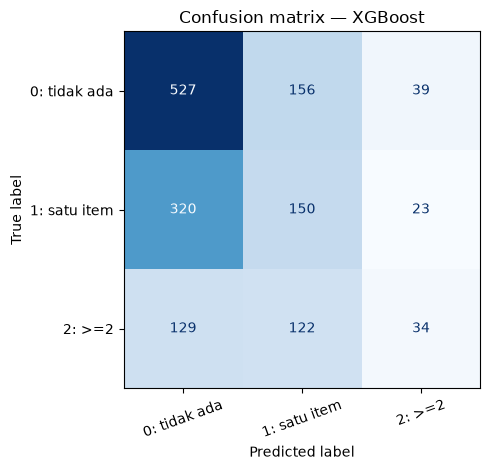

Tabel evaluasi tersimpan : Clustering_Stok\eval_ml_xgboost.csv
Prediksi tersimpan       : Clustering_Stok\prediksi_xgboost.csv


In [6]:
mulai = time.time()
xgb_cls = XGBClassifier(
    objective='multi:softprob', num_class=3, eval_metric='mlogloss',
    n_estimators=250, max_depth=5, learning_rate=0.05,
    subsample=0.9, colsample_bytree=0.9, reg_lambda=1.0,
    tree_method='hist', n_jobs=-1, random_state=SEED
)
xgb_cls.fit(X_train_encoded, y_cls_train)
pred_cls = xgb_cls.predict(X_test_encoded)

xgb_reg = XGBRegressor(
    objective='reg:squarederror', eval_metric='rmse',
    n_estimators=250, max_depth=5, learning_rate=0.05,
    subsample=0.9, colsample_bytree=0.9, reg_lambda=1.0,
    tree_method='hist', n_jobs=-1, random_state=SEED
)
xgb_reg.fit(X_train_encoded, y_reg_train)
pred_reg = xgb_reg.predict(X_test_encoded)
waktu = time.time() - mulai

hasil_xgb, prediksi_xgb = simpan_hasil_model('XGBoost', pred_cls, pred_reg, waktu)

## 6. Interpretasi dan file hasil

`eval_ml_*.csv` menyimpan metrik model dan baseline. `prediksi_*.csv` menyimpan tanggal, produk, outlet, nilai aktual, kelas prediksi, dan prediksi kuantitas. Gunakan notebook `14_Perbandingan_ML.ipynb` untuk menggabungkan semua hasil.